# Conexión y Librerías

Conectar con el drive en el siguiente enlace ->



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

directorio = '/content/drive/MyDrive/Programacion/Python/Bots/SmartOVI'

Mounted at /content/drive


Accedemos a la carpeta con el dataset e importamos las librerias

In [ ]:
import cv2
from matplotlib import pyplot as pltd
import numpy as np

# Aplicación de Filtros



Primeramente convertimos a escala de grises

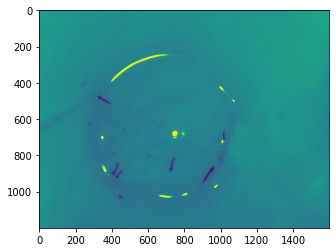

In [ ]:
imagen = cv2.imread(directorio + '/dataset/' + '202210242016.jpg')
grises = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

pltd.imshow(grises)
pltd.show()

Luego umbralizamos con parámetros estáticos

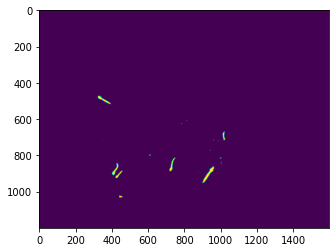

In [ ]:
_,th = cv2.threshold(grises, 85, 255, cv2.THRESH_BINARY_INV)

pltd.imshow(th)
pltd.show()

Luego iteramos con operaciónes morfológicas sobre el resultado para eliminar el ruido, especificamente la operación de apertura

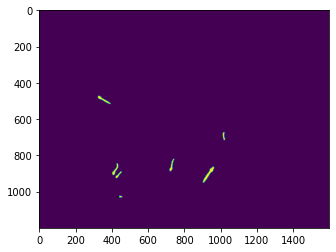

In [ ]:
kernel = np.ones((5,5),np.uint8)
opening = cv2.morphologyEx(th, cv2.MORPH_OPEN,kernel)

pltd.imshow(opening)
pltd.show()

# Evaluación de contornos

Se implementa el algoritmo de detección de contornos

In [ ]:
cnts,_ = cv2.findContours(opening,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)


Se recorre los contornos detectados y se evalua el área de los rectángulos circunscriptos

In [ ]:
cLarvas = 0

for contorno in cnts:
    (x,y,w,h) = cv2.boundingRect(contorno)
    if w>11 and h>11:
        cv2.rectangle(imagen,(x,y),(x+w,y+h),(255,0,0),2)
        cLarvas=cLarvas+1

Se imprime cantidad de larvas detectadas y el resultado

La cantidad de larvas detectadas es : 6


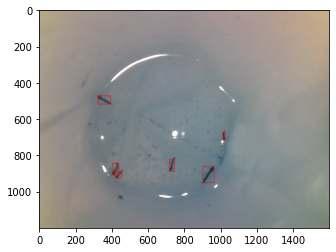

In [ ]:
print('La cantidad de larvas detectadas es :', cLarvas)
pltd.imshow(imagen)
pltd.show()

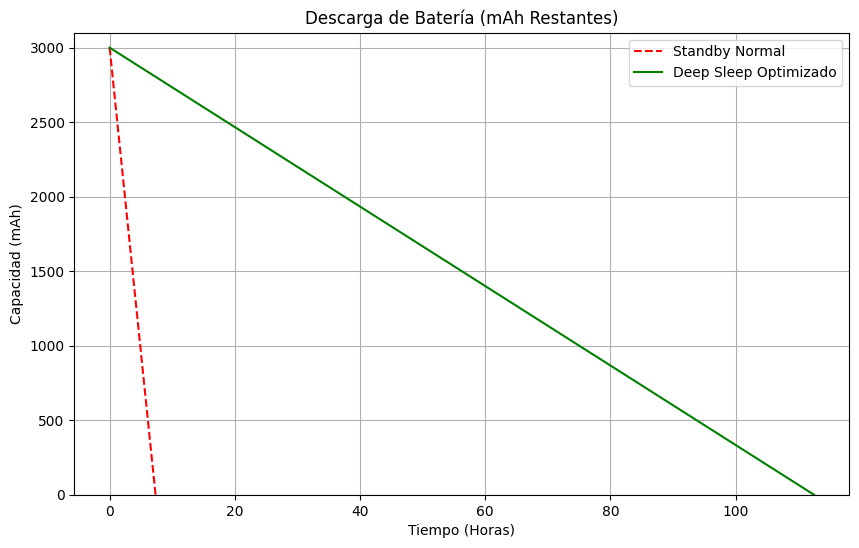

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Parámetros
BATTERY_CAPACITY_MAH = 3000
I_LEDS_50_PERCENT = 150
I_ESP32_ACTIVE = 250
I_TRANSISTORS = 10
I_TOTAL_ACTIVE = I_LEDS_50_PERCENT + I_ESP32_ACTIVE + I_TRANSISTORS

I_IDLE = I_TOTAL_ACTIVE      # Mal escenario
I_DEEP_SLEEP = 10 # Buen escenario

CYCLE_INTERVAL_MINUTES = 2
ACTIVE_DURATION_SECONDS = 5
CYCLE_TOTAL_SECONDS = CYCLE_INTERVAL_MINUTES * 60
SLEEP_DURATION_SECONDS = CYCLE_TOTAL_SECONDS - ACTIVE_DURATION_SECONDS

def simulate_discharge(standby_current_ma):
    capacity_remaining = [BATTERY_CAPACITY_MAH]
    time_hours = [0]
    current_capacity = BATTERY_CAPACITY_MAH
    hours = 0

    # Cálculo de consumo por ciclo en mAh
    active_consumption = I_TOTAL_ACTIVE * (ACTIVE_DURATION_SECONDS / 3600)
    sleep_consumption = standby_current_ma * (SLEEP_DURATION_SECONDS / 3600)
    cycle_consumption = active_consumption + sleep_consumption

    while current_capacity > 0:
        current_capacity -= cycle_consumption
        hours += (CYCLE_INTERVAL_MINUTES / 60)
        if current_capacity < 0: current_capacity = 0

        capacity_remaining.append(current_capacity)
        time_hours.append(hours)

    return time_hours, capacity_remaining

time_idle, cap_idle = simulate_discharge(I_IDLE)
time_sleep, cap_sleep = simulate_discharge(I_DEEP_SLEEP)

plt.figure(figsize=(10, 6))

# Graficar mAh
plt.plot(time_idle, cap_idle, label='Standby Normal', color='red', linestyle='--')
plt.plot(time_sleep, cap_sleep, label='Deep Sleep Optimizado', color='green')

plt.title('Descarga de Batería (mAh Restantes)')
plt.xlabel('Tiempo (Horas)')
plt.ylabel('Capacidad (mAh)')
plt.ylim(0, 3100) # Eje Y empieza en 0
plt.grid(True)
plt.legend()
plt.show()